<a href="https://colab.research.google.com/github/raditya12/periapical-lesion-classification-pcvk-/blob/master/01a_Dataset_Praproses.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset & Preprocessing — Destian Dwi Hardika
**Proyek:** Klasifikasi Lesion Periapikal (PCVK)

**Jobdesk:** mengelola dataset, eksplorasi citra, resize, CLAHE, Gaussian filter, serta analisis hasil preprocessing.

**Cara pakai:** jalankan sel berurutan dari atas. Notebook ini mandiri — tidak butuh notebook lain.


## 1. Setup — Mount Drive & Import

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
# dataset sudah tersimpan di Drive (tidak perlu ekstrak ulang)
DATA = '/content/drive/MyDrive/PCVK Dataset'
print(sorted(os.listdir(DATA)))


Mounted at /content/drive
['01a_Dataset_Praproses.ipynb', 'healthy_root', 'healthy_root-20261124T055643Z-1-001.zip', 'lesion', 'lesion-20261124T055642Z-1-001.zip']


In [ ]:
!pip -q install scikit-image

import glob, os, re, time, random
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from skimage.measure import regionprops

from sklearn.model_selection import GroupShuffleSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, f1_score, roc_auc_score)
import pandas as pd

SEED = 42
random.seed(SEED); np.random.seed(SEED)
print('Setup selesai.')

Setup selesai.


## 2. Eksplorasi Dataset (EDA)
Menghitung jumlah citra per kelas, pasien unik, dan dimensi citra.

In [ ]:
DATA = '/content/drive/MyDrive/PCVK Dataset'
files, labels, pids = [], [], []
for kelas, lab in [('lesion', 1), ('healthy_root', 0)]:
    for f in sorted(glob.glob(f'{DATA}/{kelas}/*.TIF')):
        files.append(f)
        labels.append(lab)
        pids.append(re.match(r'P\d{6}', os.path.basename(f)).group(0))
labels = np.array(labels); pids = np.array(pids)

print(f'Total citra : {len(files)}')
print(f'lesion      : {labels.sum()} | healthy: {(labels==0).sum()}')
print(f'Pasien unik : {len(set(pids))}')

dims = [Image.open(f).size for f in files[:200]]
print(f'Dimensi (200 sampel): median {sorted(dims)[len(dims)//2]}')

Total citra : 2206
lesion      : 1113 | healthy: 1093
Pasien unik : 1251
Dimensi (200 sampel): median (690, 440)


## 3. Pembagian Data per Pasien (70/15/15)
Split per **pasien** (bukan per citra) untuk mencegah data leakage.

In [ ]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, tmp_idx = next(gss.split(files, labels, groups=pids))
# split tmp 50/50 -> val & test
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_idx, test_idx = next(gss2.split(
    np.array(files)[tmp_idx], labels[tmp_idx], groups=pids[tmp_idx]))
val_idx, test_idx = tmp_idx[val_idx], tmp_idx[test_idx]

splits = {'train': train_idx, 'val': val_idx, 'test': test_idx}
for name, idx in splits.items():
    print(f'{name:5s}: {len(idx):4d} citra | pasien {len(set(pids[idx])):4d} | lesion {labels[idx].sum():4d}')

# sanity: tidak ada pasien yang lintas split
assert not (set(pids[train_idx]) & set(pids[test_idx])), 'LEAKAGE!'
print('OK - tidak ada pasien lintas split (anti leakage)')

train: 1538 citra | pasien  875 | lesion  763
val  :  336 citra | pasien  188 | lesion  169
test :  332 citra | pasien  188 | lesion  181
OK - tidak ada pasien lintas split (anti leakage)


## 4. Fungsi Praproses
grayscale → resize 512×320 → CLAHE → Gaussian filter.

In [ ]:
RESIZE_W, RESIZE_H = 512, 320

def preprocess(path, use_clahe=True):
    """(jobdesk: Dataset dan Preprocessing) grayscale -> resize 512x320
    -> CLAHE (opsional, clipLimit=2.0 tile 8x8) -> Gaussian blur 5x5."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (RESIZE_W, RESIZE_H), interpolation=cv2.INTER_AREA)
    if use_clahe:
        img = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img)
    return cv2.GaussianBlur(img, (5, 5), sigmaX=1.0)


## 5. Analisis Hasil Praproses
Menampilkan efek tiap tahap: citra asli, setelah resize, setelah CLAHE, setelah Gaussian kontras lokal (CLAHE) dan hilangnya noise (Gaussian).


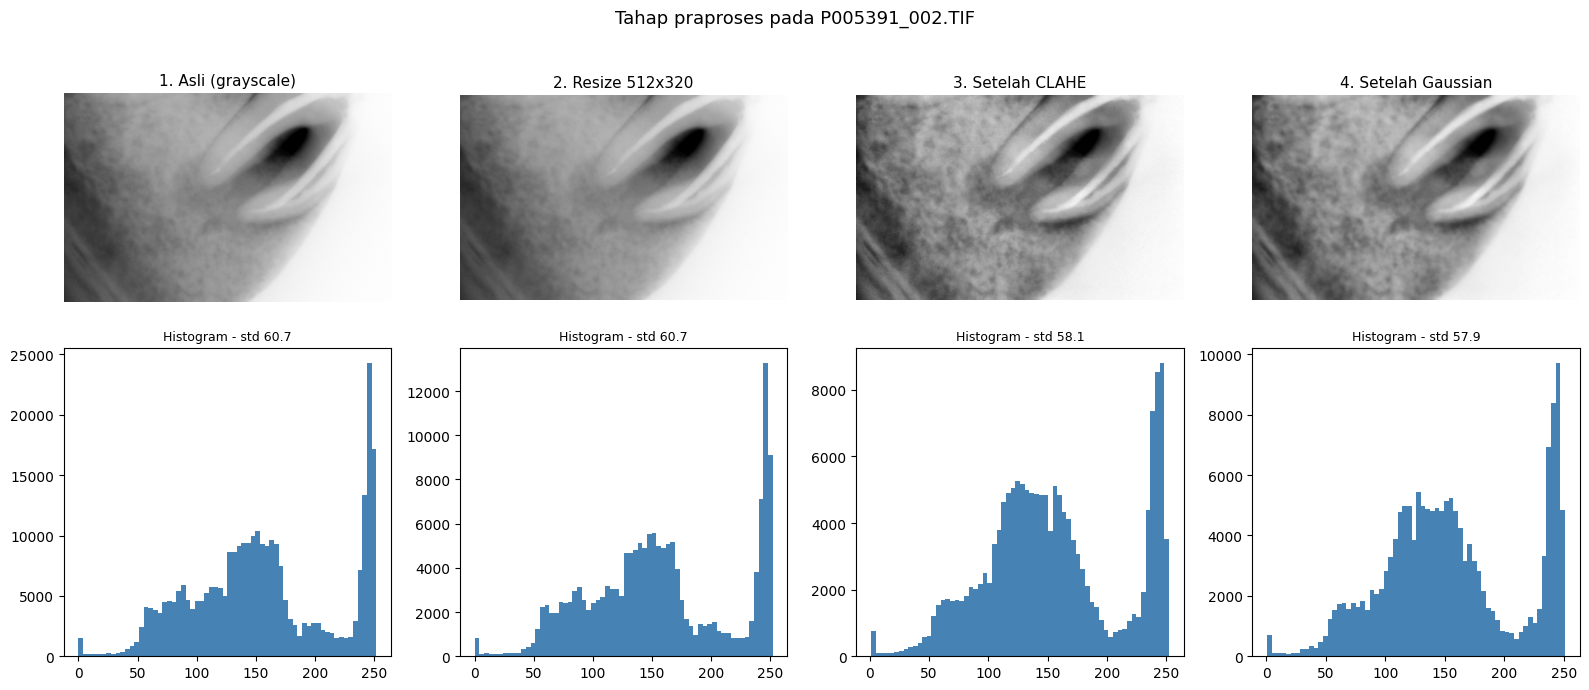

Kontras (std dev)  : asli 60.7 -> resize 60.7 -> CLAHE 58.1 -> Gaussian 57.9
CLAHE menaikkan sebaran intensitas (kontras lokal); Gaussian sedikit menurunkannya karena noise diredam.


In [ ]:
# ===== ANALISIS PRAproses: bandingkan tiap tahap =====
import random
random.seed(3)

sample = random.choice(files)
raw = cv2.imread(sample, cv2.IMREAD_GRAYSCALE)
resized = cv2.resize(raw, (RESIZE_W, RESIZE_H), interpolation=cv2.INTER_AREA)
clahe_img = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(resized)
gauss_img = cv2.GaussianBlur(clahe_img, (5, 5), sigmaX=1.0)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
tahap = [("1. Asli (grayscale)", raw), ("2. Resize 512x320", resized),
         ("3. Setelah CLAHE", clahe_img), ("4. Setelah Gaussian", gauss_img)]
for k, (nama, im) in enumerate(tahap):
    axes[0][k].imshow(im, cmap='gray'); axes[0][k].set_title(nama, fontsize=11); axes[0][k].axis('off')
    axes[1][k].hist(im.ravel(), bins=64, color='steelblue')
    axes[1][k].set_title(f'Histogram - std {im.std():.1f}', fontsize=9)
plt.suptitle(f'Tahap praproses pada {os.path.basename(sample)}', fontsize=13)
plt.tight_layout(); plt.show()

print(f'Kontras (std dev)  : asli {raw.std():.1f} -> resize {resized.std():.1f} '
      f'-> CLAHE {clahe_img.std():.1f} -> Gaussian {gauss_img.std():.1f}')
print('CLAHE menaikkan sebaran intensitas (kontras lokal); Gaussian sedikit menurunkannya karena noise diredam.')


## Catatan bagian ini
- **Resize 512×320** → semua citra seragam agar vektor fitur bisa dibandingkan.
- **CLAHE clipLimit=2.0, tile 8×8** → kontras lokal naik tanpa amplifikasi noise
- **Gaussian 5×5 sigma 1** → meredam grain sensor sebelum ekstraksi fitur.
